<a href="https://colab.research.google.com/github/EMR6040/mnist-mlp/blob/main/Yapay_Sinir_A%C4%9Flar%C4%B1_HW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cihaz: cuda
Train: 50000 | Validation: 10000 | Test: 10000
Tensör şekli: torch.Size([1, 28, 28]) | Etiket: 5


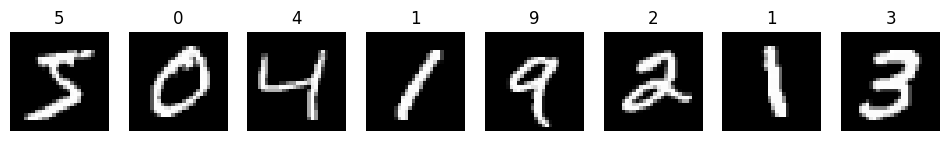

In [ ]:
import time, json, os
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Cihaz:", device)

MNIST_MEAN, MNIST_STD = 0.1307, 0.3081
tfm = transforms.Compose([transforms.ToTensor(),
                          transforms.Normalize((MNIST_MEAN,), (MNIST_STD,))])

full_train = datasets.MNIST("data", train=True, download=True, transform=tfm)
test_set   = datasets.MNIST("data", train=False, download=True, transform=tfm)

train_set, val_set = random_split(
    full_train, [50000, 10000], generator=torch.Generator().manual_seed(42))

print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")

BATCH = 128
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=1000)
test_loader  = DataLoader(test_set, batch_size=1000)

# Görsel kontrol
x, y = full_train[0]
print("Tensör şekli:", x.shape, "| Etiket:", y)
fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i, a in enumerate(ax):
    img, lbl = datasets.MNIST("data", train=True)[i]
    a.imshow(img, cmap="gray"); a.set_title(lbl); a.axis("off")
plt.show()


In [ ]:
class MLP(nn.Module):
    def __init__(self, hidden=(256, 128), num_classes=10, dropout=0.0):
        super().__init__()
        layers, in_dim = [nn.Flatten()], 28 * 28
        for h in hidden:
            layers += [nn.Linear(in_dim, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            in_dim = h
        layers.append(nn.Linear(in_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


HIDDEN = (256, 128)
LR = 1e-3
EPOCHS = 20

model = MLP(HIDDEN).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

print(model)
n_params = sum(p.numel() for p in model.parameters())
print("Toplam parametre sayısı:", n_params)


x, y = next(iter(train_loader))
with torch.no_grad():
    print("Başlangıç loss:", criterion(model(x.to(device)), y.to(device)).item())

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Toplam parametre sayısı: 235146
Başlangıç loss: 2.3022172451019287


In [ ]:
def run_epoch(model, loader, criterion, device, optimizer=None):
    """optimizer verilirse eğitim, verilmezse değerlendirme yapar."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val = float("inf")
os.makedirs("results", exist_ok=True)

start = time.time()
for ep in range(1, EPOCHS + 1):
    tl, ta = run_epoch(model, train_loader, criterion, device, optimizer)
    vl, va = run_epoch(model, val_loader, criterion, device)
    for k, v in zip(hist, (tl, vl, ta, va)):
        hist[k].append(v)
    if vl < best_val:
        best_val = vl
        torch.save(model.state_dict(), "results/best_model.pt")
    print(f"Epoch {ep:02d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
train_time = time.time() - start
print(f"\nEğitim süresi: {train_time:.1f} sn")

Epoch 01/20 | train loss 0.2999 acc 0.9106 | val loss 0.1624 acc 0.9506
Epoch 02/20 | train loss 0.1136 acc 0.9654 | val loss 0.1223 acc 0.9632
Epoch 03/20 | train loss 0.0764 acc 0.9761 | val loss 0.0958 acc 0.9685
Epoch 04/20 | train loss 0.0569 acc 0.9818 | val loss 0.0860 acc 0.9752
Epoch 05/20 | train loss 0.0425 acc 0.9861 | val loss 0.0985 acc 0.9708
Epoch 06/20 | train loss 0.0347 acc 0.9891 | val loss 0.0973 acc 0.9742
Epoch 07/20 | train loss 0.0289 acc 0.9906 | val loss 0.0855 acc 0.9763
Epoch 08/20 | train loss 0.0218 acc 0.9931 | val loss 0.1011 acc 0.9729
Epoch 09/20 | train loss 0.0214 acc 0.9927 | val loss 0.0912 acc 0.9753
Epoch 10/20 | train loss 0.0167 acc 0.9948 | val loss 0.1004 acc 0.9765
Epoch 11/20 | train loss 0.0151 acc 0.9949 | val loss 0.1015 acc 0.9749
Epoch 12/20 | train loss 0.0167 acc 0.9945 | val loss 0.1216 acc 0.9721
Epoch 13/20 | train loss 0.0153 acc 0.9946 | val loss 0.0937 acc 0.9763
Epoch 14/20 | train loss 0.0106 acc 0.9966 | val loss 0.0988 acc

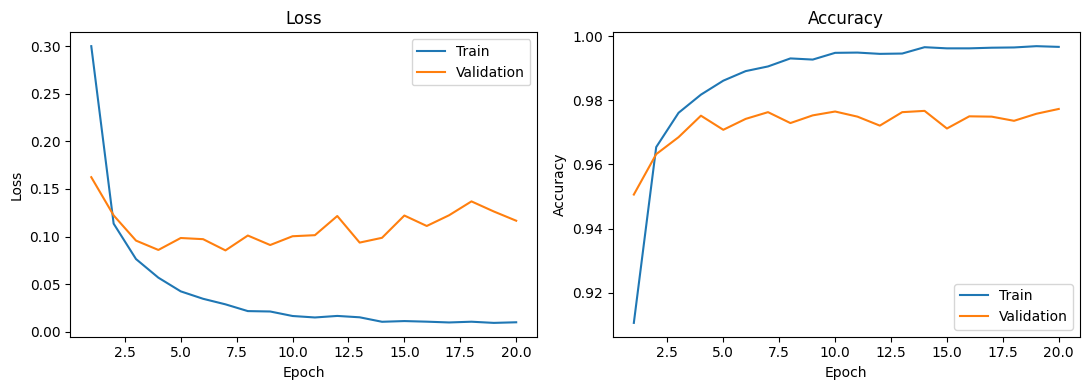

En iyi epoch (val loss'a göre): 7
  Train loss 0.0289 | acc 0.9906
  Val   loss 0.0855 | acc 0.9763

===== SON EPOCH (20) =====
Training loss     : 0.0101
Validation loss   : 0.1167
Training accuracy : 0.9967
Validation acc.   : 0.9773

===== TEST (en iyi model) =====
Test loss         : 0.0875
Test accuracy     : 0.9774
Eğitim süresi     : 238.6 sn


In [ ]:

ep_axis = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep_axis, hist["train_loss"], label="Train")
ax[0].plot(ep_axis, hist["val_loss"], label="Validation")
ax[0].set(title="Loss", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
ax[1].plot(ep_axis, hist["train_acc"], label="Train")
ax[1].plot(ep_axis, hist["val_acc"], label="Validation")
ax[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
plt.tight_layout()
plt.savefig("results/training_curves.png", dpi=150)
plt.show()


best_ep = int(np.argmin(hist["val_loss"]))
print(f"En iyi epoch (val loss'a göre): {best_ep + 1}")
print(f"  Train loss {hist['train_loss'][best_ep]:.4f} | acc {hist['train_acc'][best_ep]:.4f}")
print(f"  Val   loss {hist['val_loss'][best_ep]:.4f} | acc {hist['val_acc'][best_ep]:.4f}")


model.load_state_dict(torch.load("results/best_model.pt", map_location=device))
test_loss, test_acc = run_epoch(model, test_loader, criterion, device)

print("\n===== SON EPOCH (20) =====")
print(f"Training loss     : {hist['train_loss'][-1]:.4f}")
print(f"Validation loss   : {hist['val_loss'][-1]:.4f}")
print(f"Training accuracy : {hist['train_acc'][-1]:.4f}")
print(f"Validation acc.   : {hist['val_acc'][-1]:.4f}")
print("\n===== TEST (en iyi model) =====")
print(f"Test loss         : {test_loss:.4f}")
print(f"Test accuracy     : {test_acc:.4f}")
print(f"Eğitim süresi     : {train_time:.1f} sn")


with open("results/results.json", "w") as f:
    json.dump({"hist": hist, "best_epoch": best_ep + 1,
               "test_loss": test_loss, "test_acc": test_acc,
               "train_time_sec": train_time}, f, indent=2)

Saving IMG_20261028_194729.jpg to IMG_20261028_194729.jpg
Yüklendi: my_digits/IMG_20261028_194729.jpg
Boyut: (13672, 1632) | Mod: RGB


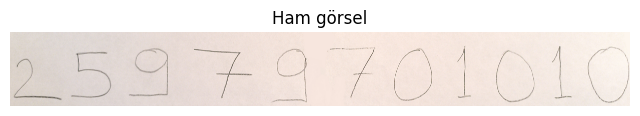

In [ ]:
from google.colab import files
from PIL import Image
import os

os.makedirs("my_digits", exist_ok=True)
uploaded = files.upload()

for name in uploaded:
    os.rename(name, f"my_digits/{name}")
    print("Yüklendi:", f"my_digits/{name}")

# Ham görseli göster
path = "my_digits/" + list(uploaded.keys())[0]
img = Image.open(path)
print("Boyut:", img.size, "| Mod:", img.mode)
plt.figure(figsize=(8, 3))
plt.imshow(img, cmap="gray"); plt.axis("off"); plt.title("Ham görsel")
plt.show()

Bulunan rakam sayısı: 11 (beklenen: 11 )
Tahmin : 25373701010
Beklenen: 25979701010
  1. rakam -> 2  (güven 99.9%)
  2. rakam -> 5  (güven 99.3%)
  3. rakam -> 3  (güven 79.8%)
  4. rakam -> 7  (güven 100.0%)
  5. rakam -> 3  (güven 73.6%)
  6. rakam -> 7  (güven 100.0%)
  7. rakam -> 0  (güven 100.0%)
  8. rakam -> 1  (güven 99.9%)
  9. rakam -> 0  (güven 99.0%)
  10. rakam -> 1  (güven 99.3%)
  11. rakam -> 0  (güven 97.8%)
Doğru rakam: 9/11


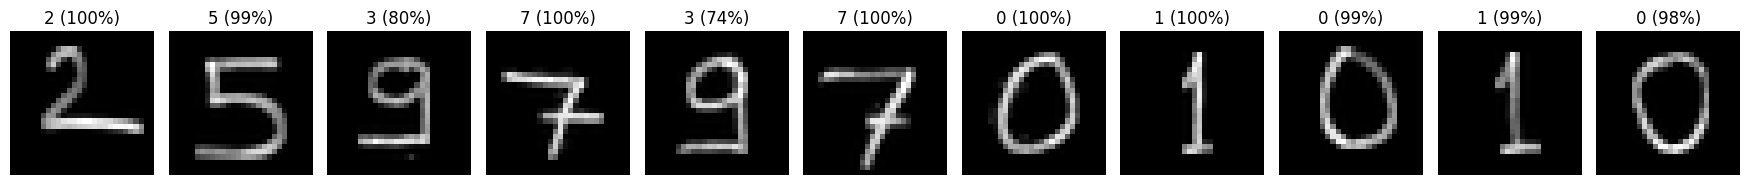

In [ ]:
from PIL import Image, ImageFilter
import numpy as np, torch
import matplotlib.pyplot as plt

PATH = "my_digits/IMG_20261028_194729.jpg"
EXPECTED = "25979701010"
THICK = 11

def load_ink(path, target_h=200):
    img = Image.open(path).convert("L")
    w, h = img.size
    img = img.resize((round(w * target_h / h), target_h), Image.LANCZOS)
    gray = np.array(img, dtype=np.float32)

    bg = img.filter(ImageFilter.MaxFilter(31)).filter(ImageFilter.GaussianBlur(10))
    ink = np.clip(np.array(bg, dtype=np.float32) - gray, 0, None)   # mürekkep = parlak
    ink = ink / ink.max() * 255
    ink[ink < 30] = 0

    ink = np.array(Image.fromarray(ink.astype(np.uint8)).filter(ImageFilter.MaxFilter(THICK)),
                   dtype=np.float32)
    return ink

def split_digits(img, min_width=5):
    ink = (img > 0).any(axis=0)
    segs, start = [], None
    for x, v in enumerate(ink):
        if v and start is None: start = x
        elif not v and start is not None:
            if x - start >= min_width: segs.append((start, x))
            start = None
    if start is not None and len(ink) - start >= min_width: segs.append((start, len(ink)))
    return [img[:, a:b] for a, b in segs]

def to_mnist_format(d):
    ys, xs = np.where(d > 0)
    d = d[ys.min():ys.max()+1, xs.min():xs.max()+1]
    h, w = d.shape
    s = 20.0 / max(h, w)
    nw, nh = max(1, round(w*s)), max(1, round(h*s))
    small = np.array(Image.fromarray(d.astype(np.uint8)).resize((nw, nh), Image.LANCZOS), dtype=np.float32)
    canvas = np.zeros((28, 28), dtype=np.float32)
    t, l = (28-nh)//2, (28-nw)//2
    canvas[t:t+nh, l:l+nw] = small
    tot = canvas.sum()
    cy = (canvas.sum(1) * np.arange(28)).sum() / tot
    cx = (canvas.sum(0) * np.arange(28)).sum() / tot
    canvas = np.roll(canvas, (round(14-cy), round(14-cx)), axis=(0, 1))
    return canvas / 255.0

ink = load_ink(PATH)
digits = split_digits(ink)
print("Bulunan rakam sayısı:", len(digits), "(beklenen:", len(EXPECTED), ")")

imgs = [to_mnist_format(d) for d in digits]
batch = (torch.tensor(np.stack(imgs)).unsqueeze(1) - MNIST_MEAN) / MNIST_STD

model.eval()
with torch.no_grad():
    probs = torch.softmax(model(batch.to(device)), dim=1).cpu()
conf, pred = probs.max(1)

result = "".join(str(int(p)) for p in pred)
print("Tahmin :", result)
print("Beklenen:", EXPECTED)
for i, (p, c) in enumerate(zip(pred, conf)):
    print(f"  {i+1}. rakam -> {int(p)}  (güven {c:.1%})")
if len(result) == len(EXPECTED):
    ok = sum(a == b for a, b in zip(result, EXPECTED))
    print(f"Doğru rakam: {ok}/{len(EXPECTED)}")

fig, ax = plt.subplots(1, len(imgs), figsize=(1.6*len(imgs), 2.4))
for a, im, p, c in zip(ax, imgs, pred, conf):
    a.imshow(im, cmap="gray"); a.axis("off"); a.set_title(f"{int(p)} ({c:.0%})")
plt.tight_layout(); plt.savefig("results/own_digits_prediction.png", dpi=150); plt.show()

In [ ]:
for idx in [2, 4]:  # 3. ve 5. rakam (0'dan başlayan indeks)
    top = probs[idx].topk(3)
    print(f"{idx+1}. rakam (gerçek: {EXPECTED[idx]}):")
    for p, c in zip(top.values, top.indices):
        print(f"   {int(c)} -> {p:.1%}")

3. rakam (gerçek: 9):
   3 -> 79.8%
   2 -> 10.3%
   5 -> 8.8%
5. rakam (gerçek: 9):
   3 -> 73.6%
   9 -> 25.4%
   5 -> 0.5%


In [ ]:
for idx in [2, 4]:
    print(f"{idx+1}. rakam -> 9 olasılığı: {probs[idx][9]:.2%}")

3. rakam -> 9 olasılığı: 0.05%
5. rakam -> 9 olasılığı: 25.41%


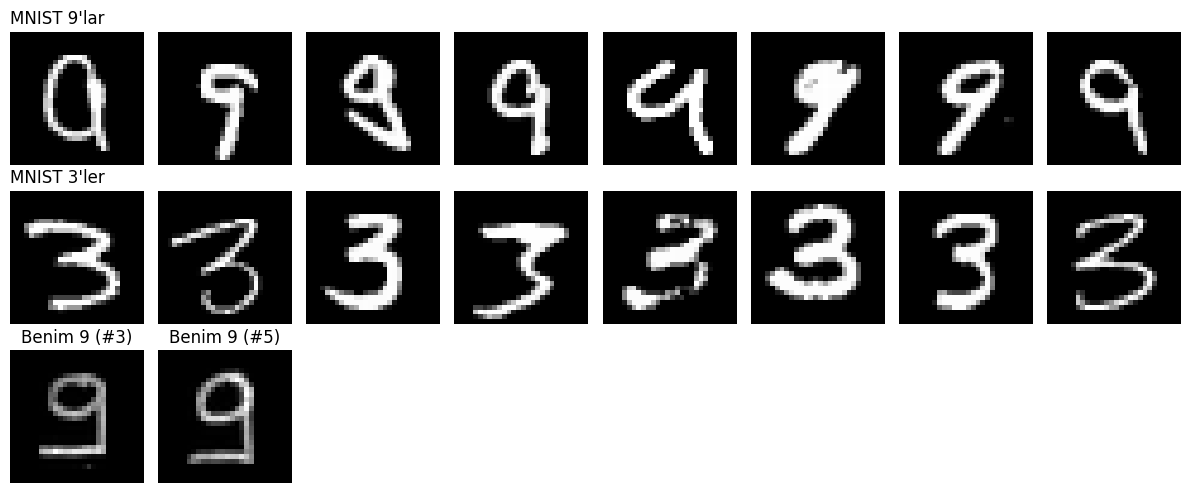

In [ ]:
raw = datasets.MNIST("data", train=True, download=False)
data, targets = raw.data.numpy(), raw.targets.numpy()

rng = np.random.default_rng(0)
nines  = rng.choice(np.where(targets == 9)[0], 8, replace=False)
threes = rng.choice(np.where(targets == 3)[0], 8, replace=False)

fig, ax = plt.subplots(3, 8, figsize=(12, 5))
for j in range(8):
    ax[0, j].imshow(data[nines[j]], cmap="gray");  ax[0, j].axis("off")
    ax[1, j].imshow(data[threes[j]], cmap="gray"); ax[1, j].axis("off")
ax[0, 0].set_title("MNIST 9'lar", loc="left")
ax[1, 0].set_title("MNIST 3'ler", loc="left")
for j, idx in enumerate([2, 4]):
    ax[2, j].imshow(imgs[idx], cmap="gray"); ax[2, j].axis("off")
    ax[2, j].set_title(f"Benim 9 (#{idx+1})")
for j in range(2, 8):
    ax[2, j].axis("off")
plt.tight_layout(); plt.savefig("results/compare_with_mnist.png", dpi=150); plt.show()